[INFO] Reading dataset: F:\GitHub_Repos\AVIATION\data\raw_data\eurostat_aviation_ghg_emissions.csv


C:\Users\spsyc\AppData\Local\Temp\ipykernel_23308\2454208620.py:63: DtypeWarning: Columns (10: CONF_STATUS) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(RAW_FILE)


[SUCCESS] Complete 3-panel figure saved to: F:\GitHub_Repos\AVIATION\reports\figures\coverag_map.png


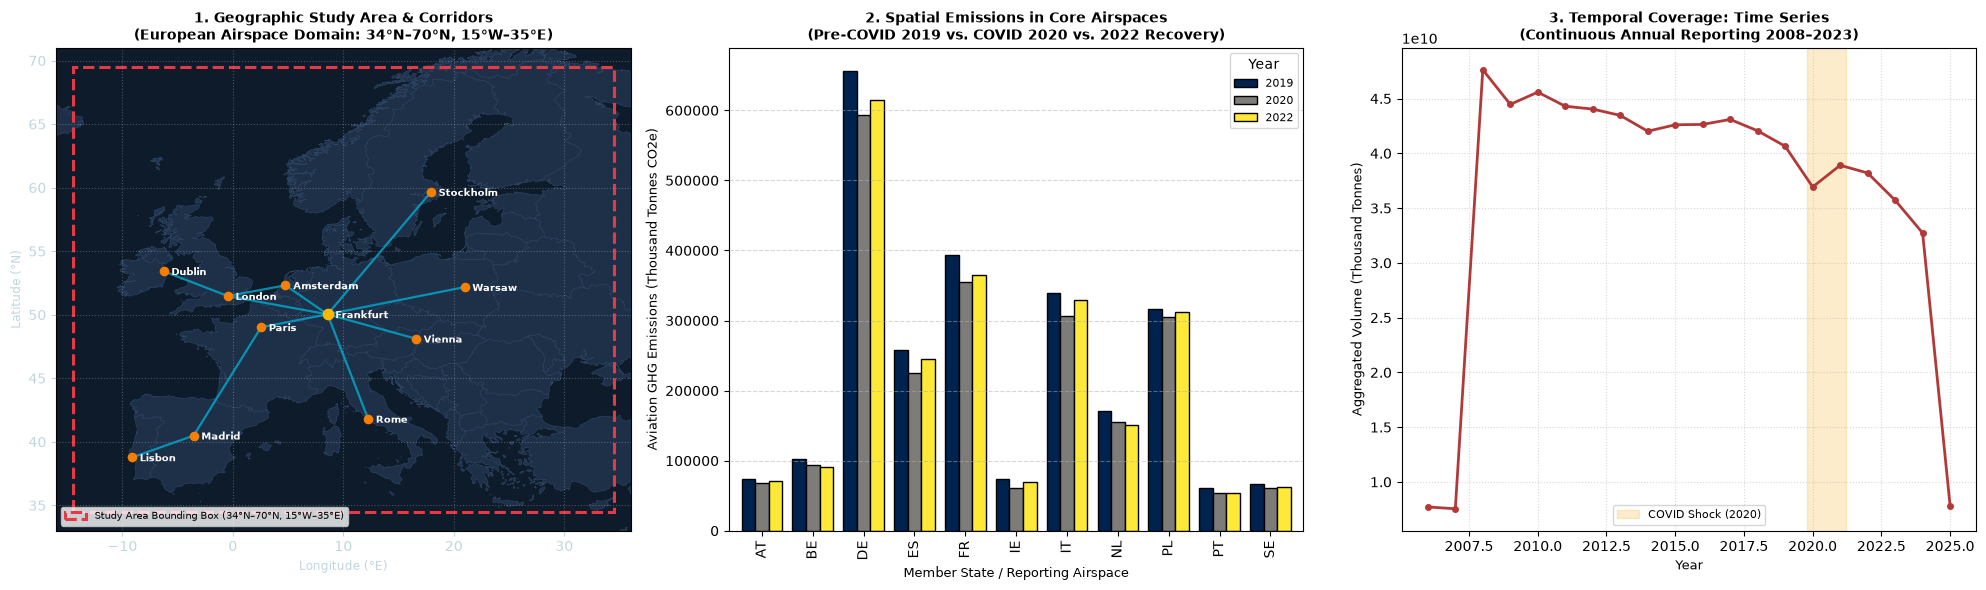

In [5]:
import json
from pathlib import Path
import sys
import urllib.request
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import pandas as pd

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    USE_CARTOPY = True
except ImportError:
    USE_CARTOPY = False

# File Paths
RAW_FILE = Path(
    "F:/GitHub_Repos/AVIATION/data/raw_data/eurostat_aviation_ghg_emissions.csv"
)
OUT_DIR = Path(
    "F:/GitHub_Repos/AVIATION/reports/figures"
)
OUT_FILE = OUT_DIR / "coverag_map.png"

# Geographic coordinates of core European airport hubs
AIRPORTS = {
    "London (LHR)": (-0.46, 51.47),
    "Paris (CDG)": (2.55, 49.01),
    "Frankfurt (FRA)": (8.57, 50.03),
    "Amsterdam (AMS)": (4.76, 52.31),
    "Madrid (MAD)": (-3.56, 40.48),
    "Rome (FCO)": (12.24, 41.80),
    "Dublin (DUB)": (-6.27, 53.42),
    "Vienna (VIE)": (16.57, 48.11),
    "Lisbon (LIS)": (-9.13, 38.77),
    "Stockholm (ARN)": (17.92, 59.65),
    "Warsaw (WAW)": (20.97, 52.17),
}

# Core high-density flight corridors
CORRIDORS = [
    ("London (LHR)", "Frankfurt (FRA)"),
    ("Paris (CDG)", "Frankfurt (FRA)"),
    ("London (LHR)", "Amsterdam (AMS)"),
    ("Paris (CDG)", "Madrid (MAD)"),
    ("Frankfurt (FRA)", "Rome (FCO)"),
    ("Frankfurt (FRA)", "Vienna (VIE)"),
    ("London (LHR)", "Dublin (DUB)"),
    ("Madrid (MAD)", "Lisbon (LIS)"),
    ("Frankfurt (FRA)", "Warsaw (WAW)"),
    ("Frankfurt (FRA)", "Stockholm (ARN)"),
    ("Amsterdam (AMS)", "Frankfurt (FRA)"),
]


def plot_coverage():
    if not RAW_FILE.exists():
        print(f"[ERROR] {RAW_FILE} not found. Check file path.")
        sys.exit(1)

    print(f"[INFO] Reading dataset: {RAW_FILE}")
    df = pd.read_csv(RAW_FILE)
    df.columns = [c.lower() for c in df.columns]

    time_col = "time_period" if "time_period" in df.columns else "time"
    val_col = "obs_value" if "obs_value" in df.columns else "value"
    geo_col = "geo" if "geo" in df.columns else "unit"

    df_clean = df[[geo_col, time_col, val_col]].dropna()
    df_clean[time_col] = pd.to_numeric(df_clean[time_col], errors="coerce")
    df_clean[val_col] = pd.to_numeric(df_clean[val_col], errors="coerce")
    df_clean = df_clean.dropna()

    # Core European flight corridor entities
    corridor_codes = [
        "DE",
        "FR",
        "ES",
        "IT",
        "NL",
        "PT",
        "AT",
        "BE",
        "PL",
        "SE",
        "IE",
    ]
    df_corr = df_clean[df_clean[geo_col].isin(corridor_codes)]
    pivot = df_corr.pivot_table(
        index=geo_col, columns=time_col, values=val_col, aggfunc="mean"
    )

    # Create unified 3-Panel Figure
    fig = plt.figure(figsize=(20, 6))

    # ========================================================
    # PANEL 1: GEOGRAPHIC MAP OF STUDY AREA & FLIGHT CORRIDORS
    # ========================================================
    if USE_CARTOPY:
        ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
        ax1.set_extent([-15, 35, 34, 70], crs=ccrs.PlateCarree())
        ax1.add_feature(cfeature.OCEAN, facecolor="#0d1b2a")
        ax1.add_feature(cfeature.LAND, facecolor="#1e3048", edgecolor="#2c4260")
        ax1.add_feature(
            cfeature.COASTLINE, linewidth=0.8, edgecolor="#5c7080", zorder=2
        )
        ax1.add_feature(
            cfeature.BORDERS,
            linestyle=":",
            linewidth=0.5,
            edgecolor="#3a506b",
            zorder=2,
        )

        # Draw red dashed study bounding box
        box_lons = [-14.5, 34.5, 34.5, -14.5, -14.5]
        box_lats = [34.5, 34.5, 69.5, 69.5, 34.5]
        ax1.plot(
            box_lons,
            box_lats,
            color="#e63946",
            linewidth=2.5,
            linestyle="--",
            transform=ccrs.PlateCarree(),
            label="Study Area Bounding Box (34°N–70°N, 15°W–35°E)",
        )

        # Plot flight corridors
        for orig, dest in CORRIDORS:
            p1, p2 = AIRPORTS[orig], AIRPORTS[dest]
            ax1.plot(
                [p1[0], p2[0]],
                [p1[1], p2[1]],
                color="#00b4d8",
                linewidth=1.6,
                alpha=0.75,
                transform=ccrs.PlateCarree(),
            )

        # Plot airport nodes
        for name, (lon, lat) in AIRPORTS.items():
            color = "#ffb703" if "FRA" in name else "#f77f00"
            size = 7 if "FRA" in name else 5
            ax1.plot(
                lon,
                lat,
                marker="o",
                color=color,
                markersize=size,
                transform=ccrs.PlateCarree(),
                zorder=5,
            )
            ax1.text(
                lon + 0.7,
                lat - 0.2,
                name.split()[0],
                color="white",
                fontsize=7.5,
                fontweight="bold",
                transform=ccrs.PlateCarree(),
                zorder=6,
            )
        ax1.legend(loc="lower left", fontsize=7.5, frameon=True)
    else:
        # Matplotlib fallback with real European coastline polygons
        ax1 = fig.add_subplot(1, 3, 1, facecolor="#0d1b2a")
        ax1.set_xlim(-16, 36)
        ax1.set_ylim(33, 71)

        geojson_url = "https://raw.githubusercontent.com/leakyMirror/map-of-europe/master/GeoJSON/europe.geojson"
        try:
            req = urllib.request.Request(
                geojson_url, headers={"User-Agent": "Mozilla/5.0"}
            )
            with urllib.request.urlopen(req, timeout=10) as response:
                geo_data = json.loads(response.read().decode())
            for feature in geo_data["features"]:
                coords = feature["geometry"]["coordinates"]
                if feature["geometry"]["type"] == "Polygon":
                    coords = [coords]
                for poly in coords:
                    xs, ys = zip(*poly[0])
                    ax1.fill(
                        xs, ys, facecolor="#1e3048", edgecolor="#2c4260", lw=0.5
                    )
        except Exception:
            ax1.fill(
                [-15, 35, 35, -15],
                [34, 34, 70, 70],
                facecolor="#1e3048",
                alpha=0.4,
            )

        # Red dashed study boundary
        rect = mpatches.Rectangle(
            (-14.5, 34.5),
            49,
            35,
            linewidth=2.2,
            edgecolor="#e63946",
            facecolor="none",
            linestyle="--",
            label="Study Area Bounding Box (34°N–70°N, 15°W–35°E)",
        )
        ax1.add_patch(rect)

        # Plot flight corridors
        for orig, dest in CORRIDORS:
            p1, p2 = AIRPORTS[orig], AIRPORTS[dest]
            ax1.plot(
                [p1[0], p2[0]],
                [p1[1], p2[1]],
                color="#00b4d8",
                linewidth=1.6,
                alpha=0.75,
            )

        # Plot airport nodes
        for name, (lon, lat) in AIRPORTS.items():
            color = "#ffb703" if "FRA" in name else "#f77f00"
            size = 55 if "FRA" in name else 35
            ax1.scatter(lon, lat, color=color, s=size, zorder=5)
            ax1.annotate(
                name.split()[0],
                (lon + 0.7, lat - 0.3),
                color="white",
                fontsize=7.5,
                fontweight="bold",
            )

        ax1.set_xlabel("Longitude (°E)", fontsize=8.5, color="#c0d6df")
        ax1.set_ylabel("Latitude (°N)", fontsize=8.5, color="#c0d6df")
        ax1.tick_params(colors="#c0d6df")
        ax1.grid(True, linestyle=":", alpha=0.25, color="white")
        ax1.legend(loc="lower left", fontsize=7.5)

    ax1.set_title(
        "1. Geographic Study Area & Corridors\n(European Airspace Domain: 34°N–70°N, 15°W–35°E)",
        fontsize=10,
        fontweight="bold",
    )

    # ========================================================
    # PANEL 2: SPATIAL COVERAGE (BAR PLOT FROM CSV)
    # ========================================================
    ax2 = fig.add_subplot(1, 3, 2)
    pivot[[2019, 2020, 2022]].plot(
        kind="bar", ax=ax2, colormap="cividis", edgecolor="black", width=0.8
    )
    ax2.set_title(
        "2. Spatial Emissions in Core Airspaces\n(Pre-COVID 2019 vs. COVID 2020 vs. 2022 Recovery)",
        fontsize=10,
        fontweight="bold",
    )
    ax2.set_ylabel("Aviation GHG Emissions (Thousand Tonnes CO2e)", fontsize=9)
    ax2.set_xlabel("Member State / Reporting Airspace", fontsize=9)
    ax2.grid(axis="y", linestyle="--", alpha=0.5)
    ax2.legend(title="Year", fontsize=8)

    # ========================================================
    # PANEL 3: TEMPORAL COVERAGE (TIME SERIES FROM CSV)
    # ========================================================
    ax3 = fig.add_subplot(1, 3, 3)
    trend = (
        df_clean[df_clean[geo_col].isin(["EU27_2020", "DE", "FR"])]
        .groupby(time_col)[val_col]
        .sum()
    )
    ax3.plot(
        trend.index,
        trend.values,
        marker="o",
        color="#b33939",
        linewidth=2,
        markersize=4,
    )
    ax3.axvspan(
        2019.8, 2021.2, color="#f7b731", alpha=0.25, label="COVID Shock (2020)"
    )
    ax3.set_title(
        "3. Temporal Coverage: Time Series\n(Continuous Annual Reporting 2008–2023)",
        fontsize=10,
        fontweight="bold",
    )
    ax3.set_xlabel("Year", fontsize=9)
    ax3.set_ylabel("Aggregated Volume (Thousand Tonnes)", fontsize=9)
    ax3.grid(True, linestyle=":", alpha=0.5)
    ax3.legend(fontsize=8)

    # Save and display
    plt.tight_layout()
    plt.savefig(OUT_FILE, dpi=300)
    print(f"[SUCCESS] Complete 3-panel figure saved to: {OUT_FILE}")
    plt.show()


if __name__ == "__main__":
    plot_coverage()